[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/04-machine-learning/notebooks/04-overfitting-cv-pipelines.ipynb)

# 04-04 · Overfitting, cross-validation, pipelines and saving models

**Goal:** the professional habits.
1. See overfitting with your own eyes.
2. Measure models fairly with **cross-validation**.
3. Avoid **data leakage** with a **pipeline**.
4. Tune settings with `GridSearchCV`.
5. Save and load the finished model with `joblib`.

## Step 1 · Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.model_selection import (train_test_split, cross_val_score, KFold,
                                     StratifiedKFold, GridSearchCV)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error

## Step 2 · Overfitting you can see

We make 20 noisy points from a smooth wave. Then we fit polynomial curves of degree 1, 4 and 15. A **polynomial** of degree d is a curve with up to d bends; higher degree = more flexible.

`PolynomialFeatures(degree)` creates columns x, x², x³, … and `LinearRegression` fits weights for them. We measure error on separate test points.

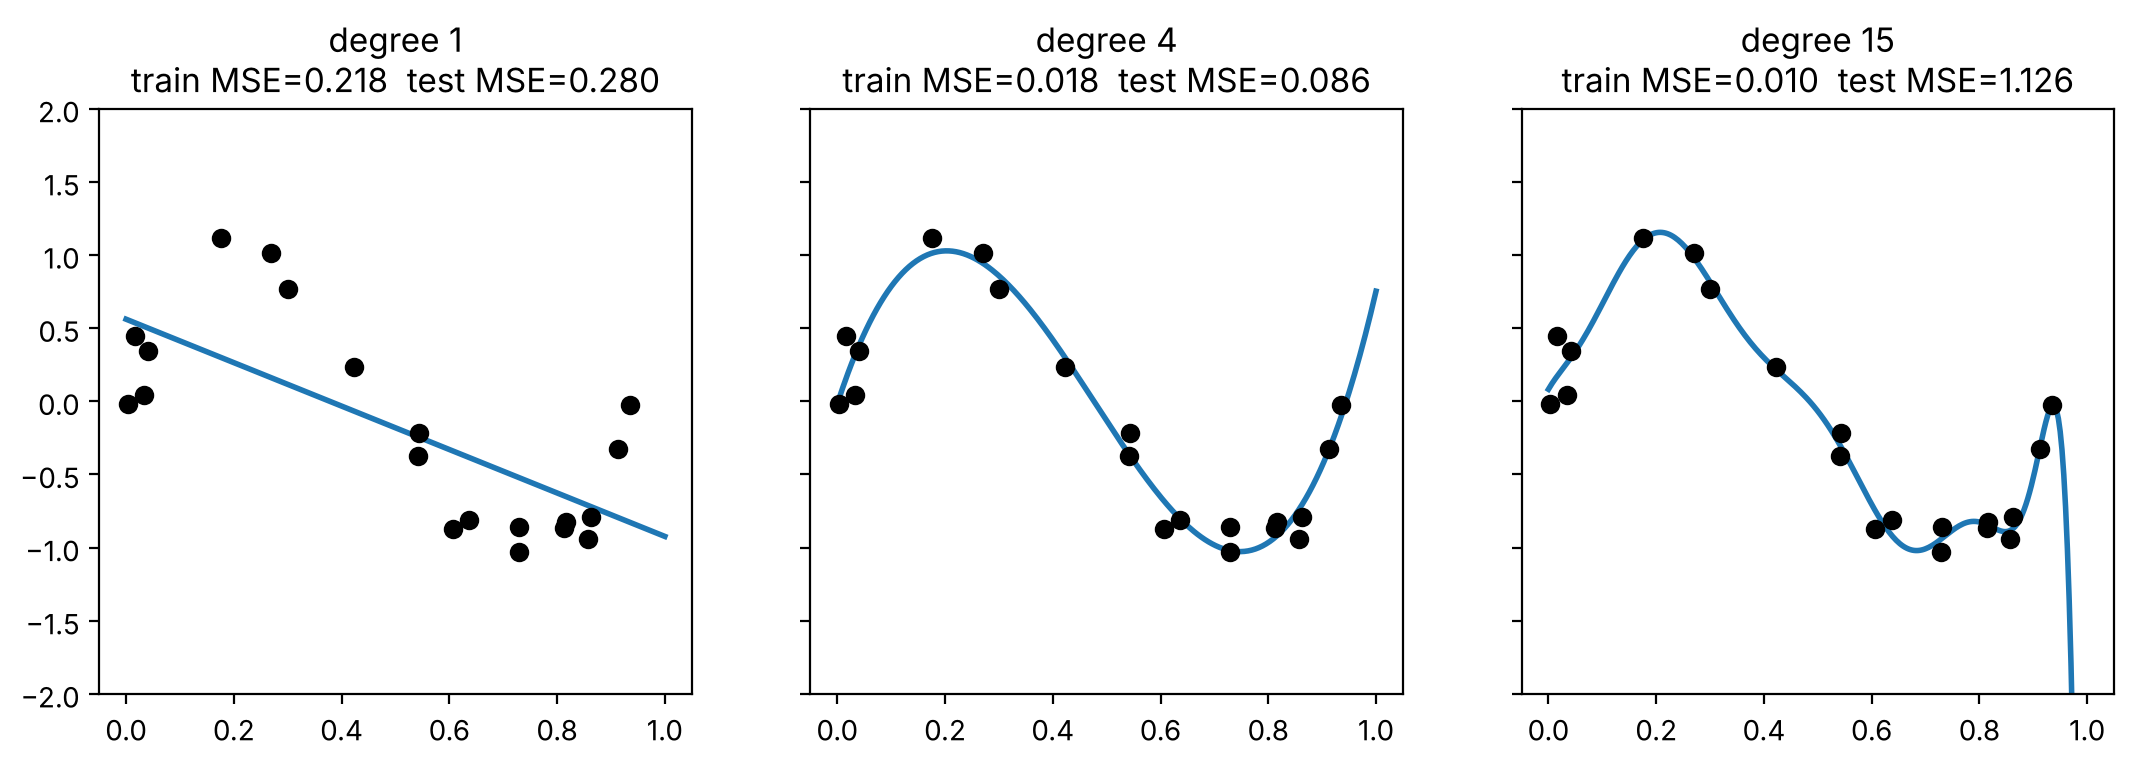

In [2]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 1, 20)).reshape(-1, 1)
y = np.sin(2 * np.pi * x).ravel() + rng.normal(0, 0.25, 20)
x_test = rng.uniform(0, 1, 100).reshape(-1, 1)
y_test = np.sin(2 * np.pi * x_test).ravel() + rng.normal(0, 0.25, 100)
grid = np.linspace(0, 1, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, degree in zip(axes, [1, 4, 15]):
    m = make_pipeline(PolynomialFeatures(degree), LinearRegression()).fit(x, y)
    tr = mean_squared_error(y, m.predict(x))
    te = mean_squared_error(y_test, m.predict(x_test))
    ax.scatter(x, y, color="black", zorder=3)
    ax.plot(grid, m.predict(grid), lw=2)
    ax.set_ylim(-2, 2)
    ax.set_title(f"degree {degree}\ntrain MSE={tr:.3f}  test MSE={te:.3f}")
plt.show()

Read the titles: degree 15 has the **lowest training error** but a **much higher test error**. It memorised the noise. Degree 1 is bad on both (underfitting). Degree 4 is the sweet spot.

## Step 3 · The train/test gap for decision trees

Same idea on real data: as `max_depth` grows, training accuracy climbs to 100% while test accuracy stalls or drops.

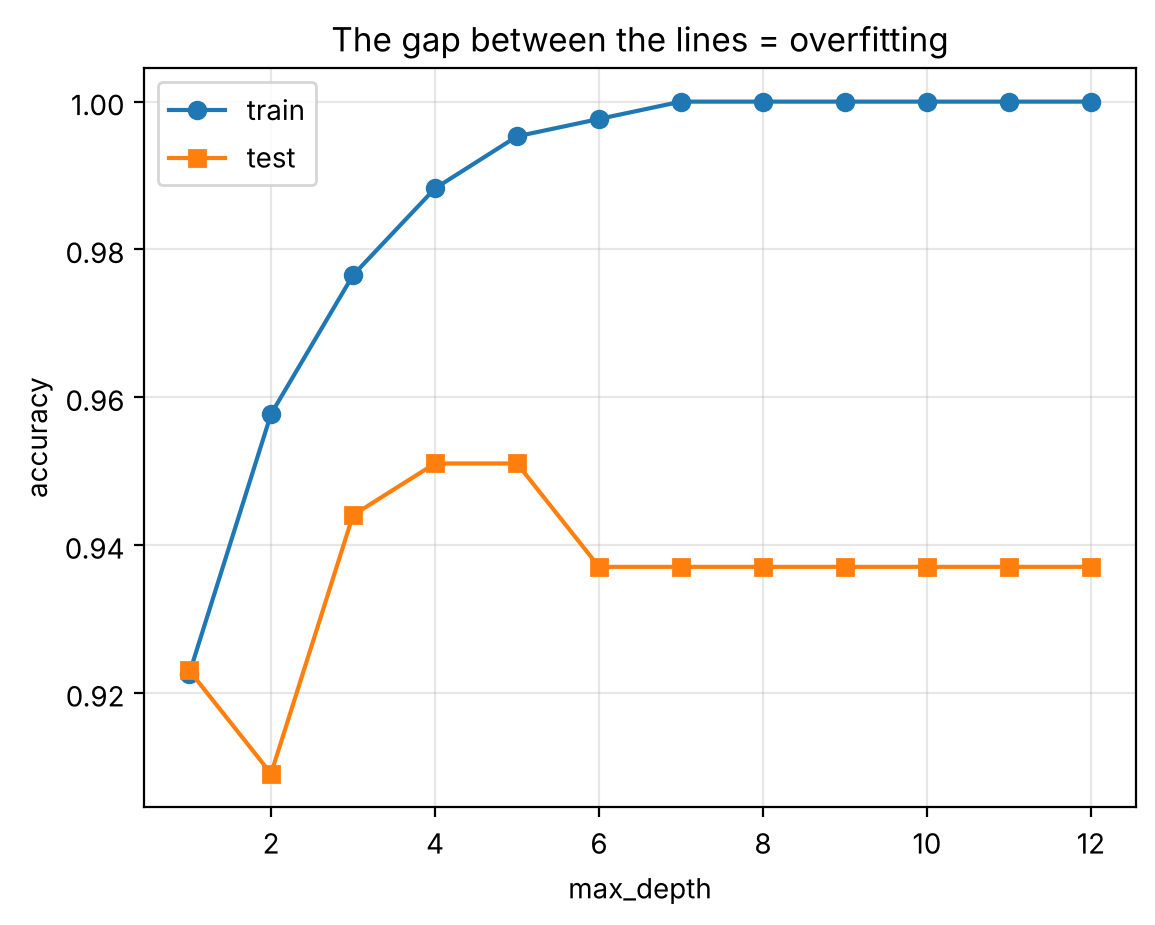

In [3]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
depths = range(1, 13)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train)); test_acc.append(t.score(X_test, y_test))
plt.plot(depths, train_acc, "o-", label="train")
plt.plot(depths, test_acc, "s-", label="test")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=0.3)
plt.title("The gap between the lines = overfitting"); plt.show()

## Step 4 · Why one split is not enough

Change only the `random_state` of the split and the test score moves around. One split is partly luck.

In [4]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
for seed in range(5):
    a, b, c, d = train_test_split(X, y, test_size=0.25, random_state=seed, stratify=y)
    print(f"split seed {seed}: test accuracy = {model.fit(a, c).score(b, d):.3f}")

split seed 0: test accuracy = 0.958
split seed 1: test accuracy = 0.965
split seed 2: test accuracy = 0.972
split seed 3: test accuracy = 0.986
split seed 4: test accuracy = 0.972


## Step 5 · k-fold cross-validation

`cross_val_score` cuts the data into k **folds**, trains on k−1, tests on the remaining one, and repeats so every fold is tested once. We get k scores; report the mean and the standard deviation (spread).

`StratifiedKFold` keeps the class mix the same in every fold; `shuffle=True` mixes rows first.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
scores = cross_val_score(model, X_train, y_train, cv=cv)
print("5 fold scores:", scores.round(3))
print(f"mean = {scores.mean():.3f}  +/- {scores.std():.3f}")

5 fold scores: [0.988 0.965 0.976 0.976 0.965]
mean = 0.974  +/- 0.009


Let us peek at what the folds are. Each round, a different fifth of the training rows is held out.

In [6]:
for i, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train), start=1):
    print(f"round {i}: train on {len(tr_idx)} rows, validate on {len(va_idx)} rows "
          f"(first validation row ids: {va_idx[:5]})")

round 1: train on 340 rows, validate on 86 rows (first validation row ids: [ 0  9 17 36 43])
round 2: train on 341 rows, validate on 85 rows (first validation row ids: [ 2  4  8 12 21])
round 3: train on 341 rows, validate on 85 rows (first validation row ids: [ 3 13 14 24 25])
round 4: train on 341 rows, validate on 85 rows (first validation row ids: [ 5  6  7 10 23])
round 5: train on 341 rows, validate on 85 rows (first validation row ids: [ 1 11 15 16 18])


## Step 6 · Comparing models fairly

Use the **same** folds for every candidate. Here: scaled logistic regression vs a single tree vs a random forest.

In [7]:
candidates = {
    "logistic (scaled)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "decision tree":     DecisionTreeClassifier(max_depth=4, random_state=0),
    "random forest":     RandomForestClassifier(n_estimators=150, random_state=0, n_jobs=1),
}
for name, m in candidates.items():
    s = cross_val_score(m, X_train, y_train, cv=cv)
    print(f"{name:18s} {s.mean():.3f} +/- {s.std():.3f}")

logistic (scaled)  0.974 +/- 0.009
decision tree      0.908 +/- 0.027


random forest      0.948 +/- 0.016


## Step 7 · Data leakage, demonstrated

**Data leakage** = information from the validation/test data sneaking into training. A classic beginner leak is choosing features using the *whole* dataset before cross-validating.

To make the effect obvious, we use pure random noise: 100 rows, 5,000 random features, random labels. No model can genuinely do better than ~50%.

- **Leaky way:** pick the 20 features most correlated with the label using *all* rows, then cross-validate.
- **Correct way:** put the feature picker *inside* a pipeline so it only sees each training fold.

`SelectKBest` keeps the k features with the strongest statistical link to the label.

In [8]:
from sklearn.feature_selection import SelectKBest, f_classif
rng = np.random.default_rng(1)
X_noise = rng.normal(size=(100, 5000))
y_noise = rng.integers(0, 2, 100)
cv_noise = StratifiedKFold(5, shuffle=True, random_state=0)

X_leaky = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)   # peeks at ALL labels
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_leaky, y_noise, cv=cv_noise).mean()

honest_pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
honest = cross_val_score(honest_pipe, X_noise, y_noise, cv=cv_noise).mean()
print(f"leaky accuracy on pure noise:  {leaky:.2f}   <- fake skill!")
print(f"honest accuracy on pure noise: {honest:.2f}   <- near a coin flip (0.5), the truth")

leaky accuracy on pure noise:  0.92   <- fake skill!
honest accuracy on pure noise: 0.58   <- near a coin flip (0.5), the truth


The leaky number looks impressive but is a lie: the data is random. (The honest number wobbles around 0.5 because 100 rows is a small sample.) **Lesson:** every step that learns from data (scaling, feature selection, filling missing values) must go *inside* the pipeline.

## Step 8 · A named Pipeline + GridSearchCV

`Pipeline` takes a list of `(name, step)` pairs. Names let us refer to a step's settings as `stepname__setting` (two underscores). `GridSearchCV` tries every combination in `param_grid` with cross-validation and keeps the best.

We use the **digits** dataset (1,797 images of 8×8 pixels, flattened to 64 numbers).

In [9]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.2, random_state=0, stratify=digits.target)

pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])
param_grid = {"model__C": [0.01, 0.1, 1.0, 10.0]}   # C: smaller = stronger regularisation
search = GridSearchCV(pipe, param_grid, cv=3, n_jobs=1)
search.fit(Xd_train, yd_train)
print("best setting:", search.best_params_)
print("best CV accuracy:", round(search.best_score_, 3))
pd.DataFrame(search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]]

best setting: {'model__C': 0.1}
best CV accuracy: 0.965


,param_model__C,mean_test_score,std_test_score
0,0.01,0.938761,0.003548
1,0.10,0.964509,0.005114
2,1.00,0.961030,0.002604
3,10.00,0.955463,0.005479


Only now, once, do we touch the test set.

In [10]:
best_model = search.best_estimator_
print("final test accuracy:", round(best_model.score(Xd_test, yd_test), 3))

final test accuracy: 0.967


## Step 9 · Save and load the model with joblib

`joblib.dump` writes the whole pipeline (scaler + model) to one file. `joblib.load` brings it back, ready to predict — no retraining.

⚠️ Only load model files you trust: loading can run code. Record your scikit-learn version alongside the file.

In [11]:
import sklearn
path = "digits_model.joblib"
joblib.dump(best_model, path)
print("saved", path, "-", round(os.path.getsize(path) / 1024, 1), "KB, sklearn", sklearn.__version__)

loaded = joblib.load(path)
print("loaded model predicts:", loaded.predict(Xd_test[:10]))
print("true labels:          ", yd_test[:10])
print("same accuracy?", loaded.score(Xd_test, yd_test) == best_model.score(Xd_test, yd_test))

os.remove(path)   # tidy up so the course folder stays clean; in a real project keep it!

saved digits_model.joblib - 7.9 KB, sklearn 1.9.1
loaded model predicts: [7 6 3 7 7 3 2 8 9 3]
true labels:           [7 6 3 7 7 3 2 8 9 3]
same accuracy? True


## Recap

- Overfitting = great on training data, worse on new data. Watch the train/test gap.
- Cross-validation gives a fairer score (mean ± spread) than one split.
- Put every data-learning step inside a `Pipeline` to avoid leakage.
- `GridSearchCV` tunes settings with CV; test set used once at the end.
- `joblib.dump` / `joblib.load` save and restore the full pipeline.